# Часть 1: Подготовка и первичный осмотр данных

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from pathlib import Path
from IPython.display import display, HTML
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 20)

In [21]:
candidates = [Path("../data/wine_quality_merged.csv"), Path("data/wine_quality_merged.csv")]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("CSV не найден. Поместите ноутбук в src, а данные — в соседнюю папку data.")
df = pd.read_csv(data_path, encoding="utf-8-sig")
english = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol", "quality", "type"]
russian = ["Нелетучая кислотность", "Летучая кислотность", "Лимонная кислота", "Остаточный сахар", "Хлориды", "Свободный диоксид серы", "Общий диоксид серы", "Плотность", "pH", "Сульфаты", "Алкоголь", "Качество", "Тип вина"]
df = df.rename(columns=dict(zip(english, russian)))
print("Количество строк и столбцов:", df.shape)
df.info()

Количество строк и столбцов: (6497, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Нелетучая кислотность   6497 non-null   float64
 1   Летучая кислотность     6497 non-null   float64
 2   Лимонная кислота        6497 non-null   float64
 3   Остаточный сахар        6497 non-null   float64
 4   Хлориды                 6497 non-null   float64
 5   Свободный диоксид серы  6497 non-null   float64
 6   Общий диоксид серы      6497 non-null   float64
 7   Плотность               6497 non-null   float64
 8   pH                      6497 non-null   float64
 9   Сульфаты                6497 non-null   float64
 10  Алкоголь                6497 non-null   float64
 11  Качество                6497 non-null   int64  
 12  Тип вина                6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660

In [22]:
display(df.head())
display(df.tail())
display(df["Тип вина"].value_counts().rename("Количество образцов").to_frame())

,Нелетучая кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Качество,Тип вина
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


,Нелетучая кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Качество,Тип вина
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,white


,Количество образцов
Тип вина,
white,4898
red,1599


In [23]:
df.isna().sum(axis=0)

Нелетучая кислотность     0
Летучая кислотность       0
Лимонная кислота          0
Остаточный сахар          0
Хлориды                   0
Свободный диоксид серы    0
Общий диоксид серы        0
Плотность                 0
pH                        0
Сульфаты                  0
Алкоголь                  0
Качество                  0
Тип вина                  0
dtype: int64

In [24]:
df.duplicated().sum()

1177

In [25]:
df[df.duplicated()].head(10)

,Нелетучая кислотность,Летучая кислотность,Лимонная кислота,Остаточный сахар,Хлориды,Свободный диоксид серы,Общий диоксид серы,Плотность,pH,Сульфаты,Алкоголь,Качество,Тип вина
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
11,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,red
27,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.9966,3.17,0.91,9.5,5,red
40,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.9978,3.33,0.83,10.5,5,red
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.9962,3.41,0.39,10.9,5,red
76,8.8,0.410,0.64,2.20,0.093,9.0,42.0,0.9986,3.54,0.66,10.5,5,red
91,8.6,0.490,0.28,1.90,0.110,20.0,136.0,0.9972,2.93,1.95,9.9,6,red
93,7.7,0.490,0.26,1.90,0.062,9.0,31.0,0.9966,3.39,0.64,9.6,5,red
102,8.1,0.545,0.18,1.90,0.080,13.0,35.0,0.9972,3.30,0.59,9.0,6,red
105,8.1,0.575,0.22,2.10,0.077,12.0,65.0,0.9967,3.29,0.51,9.2,5,red


Пропусков, распознанных pandas, нет. Обнаружено 1177 полных повторов сверх первого вхождения. Основной анализ выполнен без их удаления: без идентификаторов образцов нельзя установить, являются ли это повторные записи или разные образцы с совпавшими характеристиками. Ниже отдельно проверяется чувствительность корреляций к удалению полных повторов. Нулевые значения отдельных концентраций не считаются пропусками автоматически.

In [26]:
description = pd.DataFrame(
    [
        ["Нелетучая кислотность", "Количественный непрерывный", "Отношений"],
        ["Летучая кислотность", "Количественный непрерывный", "Отношений"],
        ["Лимонная кислота", "Количественный непрерывный", "Отношений"],
        ["Остаточный сахар", "Количественный непрерывный", "Отношений"],
        ["Хлориды", "Количественный непрерывный", "Отношений"],
        ["Свободный диоксид серы", "Количественный непрерывный", "Отношений"],
        ["Общий диоксид серы", "Количественный непрерывный", "Отношений"],
        ["Плотность", "Количественный непрерывный", "Отношений"],
        ["pH", "Количественный непрерывный", "Интервальная (логарифмическая)"],
        ["Сульфаты", "Количественный непрерывный", "Отношений"],
        ["Алкоголь", "Количественный непрерывный", "Отношений"],
        ["Качество", "Категориальный порядковый", "Порядковая"],
        ["Тип вина", "Категориальный номинальный", "Номинальная"],
    ],
    columns=["Признак", "Тип признака", "Шкала измерений"]
)

description

,Признак,Тип признака,Шкала измерений
0,Нелетучая кислотность,Количественный непрерывный,Отношений
1,Летучая кислотность,Количественный непрерывный,Отношений
2,Лимонная кислота,Количественный непрерывный,Отношений
3,Остаточный сахар,Количественный непрерывный,Отношений
4,Хлориды,Количественный непрерывный,Отношений
5,Свободный диоксид серы,Количественный непрерывный,Отношений
6,Общий диоксид серы,Количественный непрерывный,Отношений
7,Плотность,Количественный непрерывный,Отношений
8,pH,Количественный непрерывный,Интервальная (логарифмическая)
9,Сульфаты,Количественный непрерывный,Отношений


In [27]:
description["Корректность среднего"] = [
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.", 
    "Допустимо как среднее значений pH, но не как средняя концентрация ионов водорода.",
    "Допустимо: количественный признак, шкала отношений.",
    "Допустимо: количественный признак, шкала отношений.", 
    "Условно допустимо при допущении равных интервалов между оценками; иначе предпочтительны медиана и мода.",
    "Недопустимо: категории без порядка; можно рассчитать долю каждого типа вина.",
]

pd.set_option("display.max_colwidth", None)
display(HTML(description.to_html(index=False).replace('<table', '<table style="text-align:left; white-space:normal"')))

Признак,Тип признака,Шкала измерений,Корректность среднего
Нелетучая кислотность,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
Летучая кислотность,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
Лимонная кислота,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
Остаточный сахар,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
Хлориды,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
Свободный диоксид серы,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
Общий диоксид серы,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
Плотность,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."
pH,Количественный непрерывный,Интервальная (логарифмическая),"Допустимо как среднее значений pH, но не как средняя концентрация ионов водорода."
Сульфаты,Количественный непрерывный,Отношений,"Допустимо: количественный признак, шкала отношений."


Концентрации измеряются в г/л, кроме свободного и общего SO₂ (мг/л). Нелетучая кислотность выражена в эквиваленте винной кислоты, летучая — уксусной, хлориды — NaCl, сульфаты — K₂SO₄. Плотность измеряется в г/см³, алкоголь — в % об., pH безразмерен. Для числовых шкал отношения разности алкоголя выражаются в процентных пунктах. Порядковое качество рассматривается отдельно; его средний балл и корреляция Пирсона используются только как условные числовые характеристики.

# Часть 2: Проверка базовых предположений (4-Plot)

## Построение Run Sequence Plot

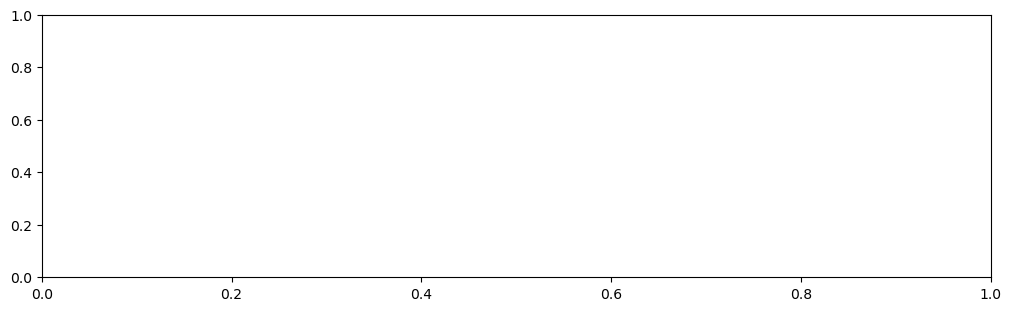

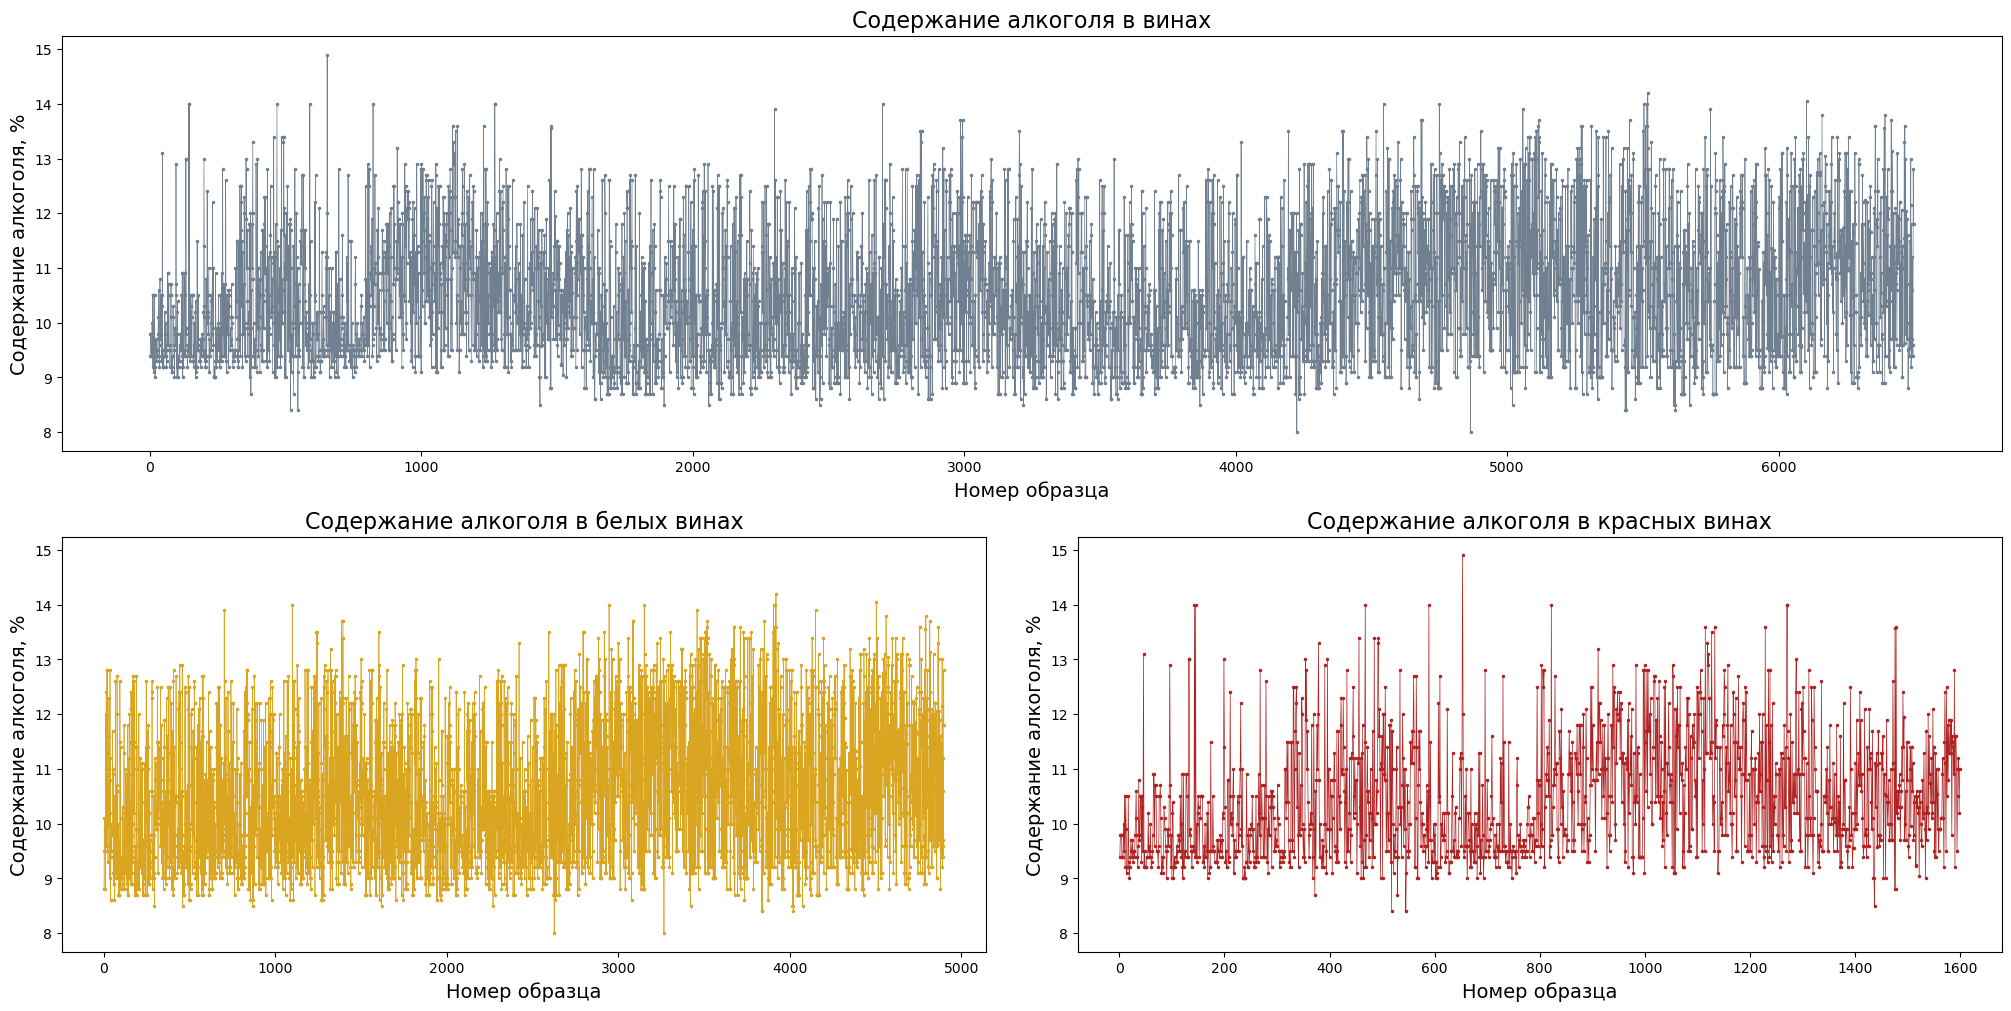

In [28]:

white_wine = df[df["Тип вина"] == "white"]
red_wine = df[df["Тип вина"] == "red"]

fig = plt.figure(figsize=(20, 10), layout="constrained")
grid = fig.add_gridspec(2, 2)

ax_all = fig.add_subplot(grid[0, :])
ax_white = fig.add_subplot(grid[1, 0], sharey=ax_all)
ax_red = fig.add_subplot(grid[1, 1], sharey=ax_all)

ax_all.plot(range(1, len(df) + 1), df["Алкоголь"], color="slategray", linewidth=0.5, marker=".", markersize=3)
ax_all.set_title("Содержание алкоголя в винах", fontsize=16)
ax_all.set_xlabel("Номер образца", fontsize=14)
ax_all.set_ylabel("Содержание алкоголя, %", fontsize=14)

ax_white.plot(range(1, len(white_wine) + 1), white_wine["Алкоголь"], color="goldenrod", linewidth=0.5, marker=".", markersize=3)
ax_white.set_title("Содержание алкоголя в белых винах", fontsize=16)
ax_white.set_xlabel("Номер образца", fontsize=14)
ax_white.set_ylabel("Содержание алкоголя, %", fontsize=14)

ax_red.plot(range(1, len(red_wine) + 1), red_wine["Алкоголь"], color="firebrick", linewidth=0.5, marker=".", markersize=3)
ax_red.set_title("Содержание алкоголя в красных винах", fontsize=16)
ax_red.set_xlabel("Номер образца", fontsize=14)
ax_red.set_ylabel("Содержание алкоголя, %", fontsize=14)



plt.show()

**Run Sequence Plot** показывает содержание алкоголя в порядке расположения образцов. Он позволяет заметить изменения положения и разброса значений, отдельные экстремальные наблюдения и различия между участками последовательности.

**Результаты:**
- **Все вина:** наблюдаются участки с разным уровнем содержания алкоголя; единого монотонного тренда не видно.
- **Белые вина:** во второй части последовательности визуально чаще встречаются повышенные значения алкоголя, что указывает на возможное изменение положения распределения.
- **Красные вина:** заметно чередование участков с более низкими и более высокими значениями, особенно около образцов 850–1200.
- Постоянство разброса по изображению однозначно оценить трудно. Отдельные пики требуют изучения и сами по себе не доказывают наличие ошибок.

Таким образом, имеются визуальные признаки неоднородности положения значений. Поскольку номер образца не является временем, эти особенности следует связывать с порядком и возможной группировкой записей, а не с изменением вина во времени. Для уточнения выводов можно сравнить средние и стандартные отклонения по последовательным блокам.

##  Построение Lag Plot

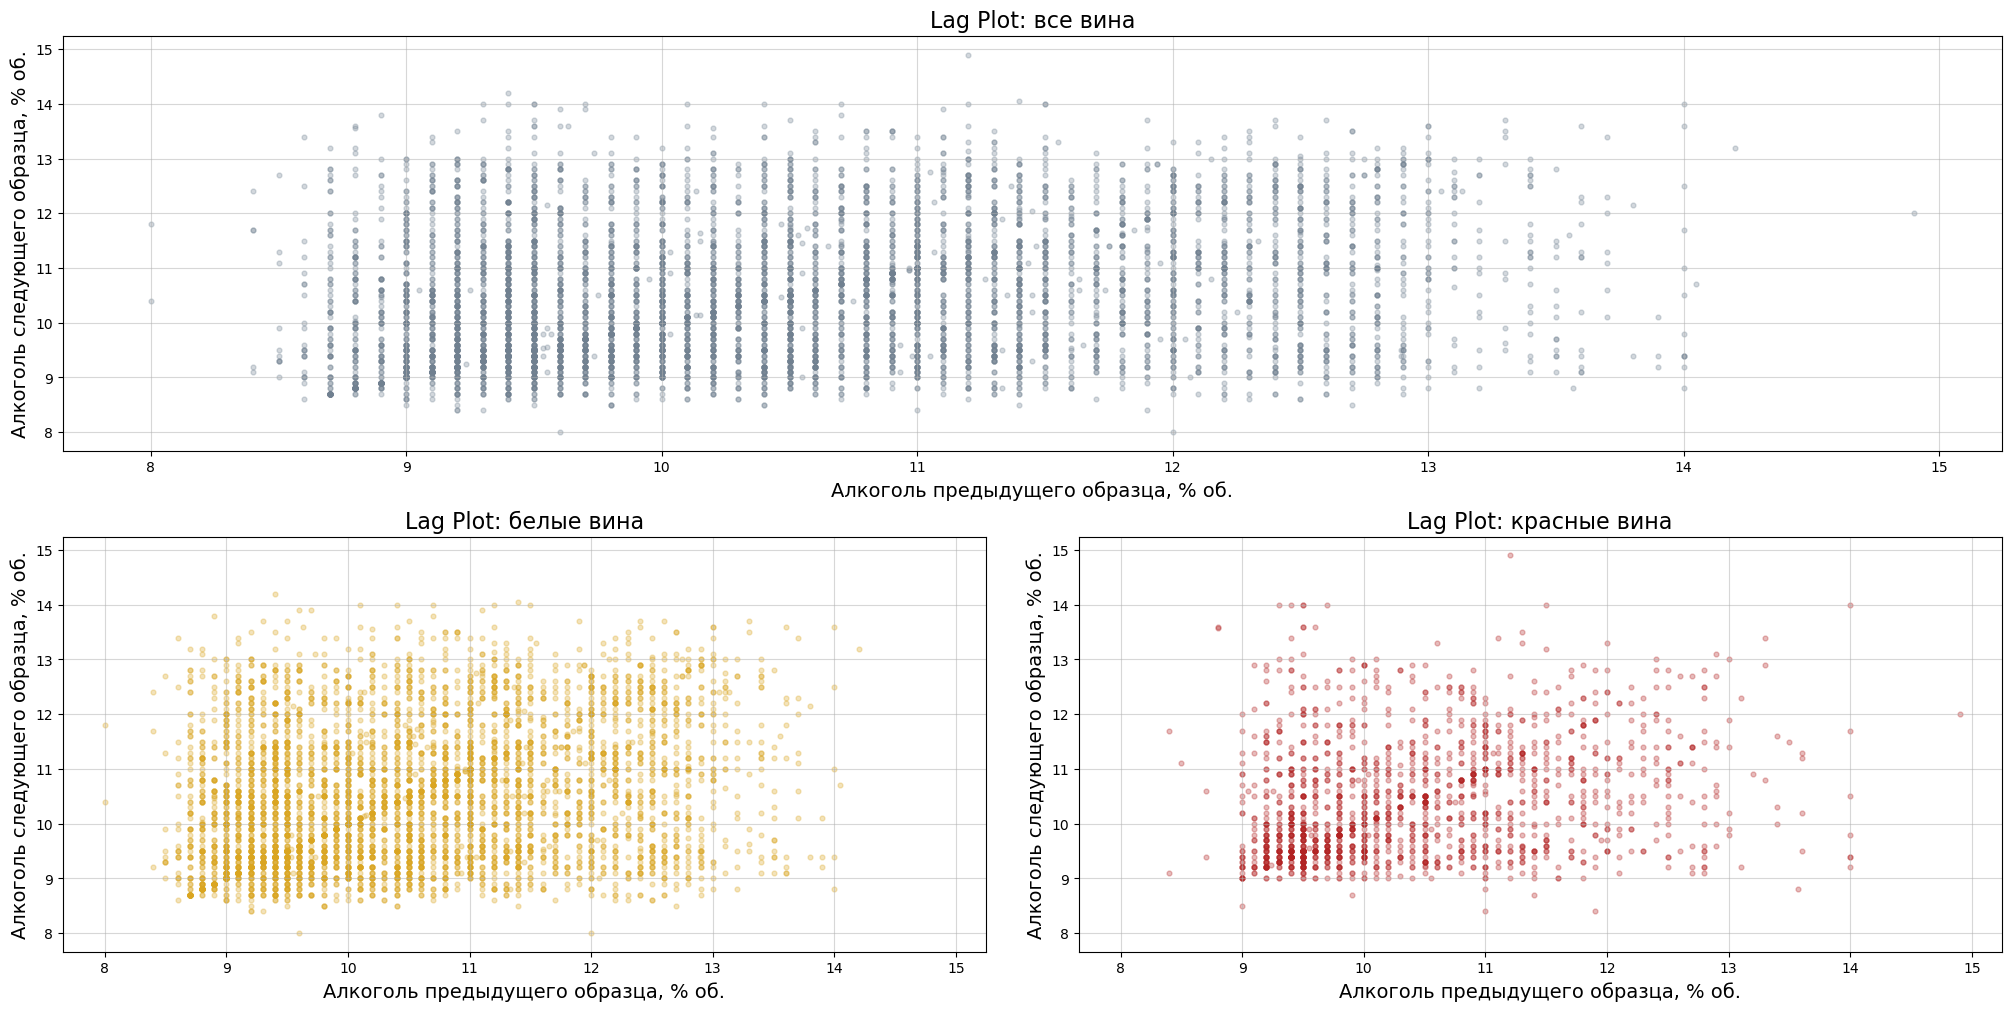

In [29]:
fig = plt.figure(figsize=(20, 10), layout="constrained")
grid = fig.add_gridspec(2, 2)

ax_all = fig.add_subplot(grid[0, :])
ax_white = fig.add_subplot(grid[1, 0], sharex=ax_all, sharey=ax_all)
ax_red = fig.add_subplot(grid[1, 1], sharex=ax_all, sharey=ax_all)

ax_all.scatter(df["Алкоголь"].iloc[:-1], df["Алкоголь"].iloc[1:], color="slategray", s=12, alpha=0.3,)
ax_all.set_title("Lag Plot: все вина", fontsize=16)

ax_white.scatter(white_wine["Алкоголь"].iloc[:-1], white_wine["Алкоголь"].iloc[1:], color="goldenrod", s=12, alpha=0.3,)
ax_white.set_title("Lag Plot: белые вина", fontsize=16)

ax_red.scatter(red_wine["Алкоголь"].iloc[:-1], red_wine["Алкоголь"].iloc[1:], color="firebrick", s=12, alpha=0.3,)
ax_red.set_title("Lag Plot: красные вина", fontsize=16)

for ax in [ax_all, ax_white, ax_red]:
    ax.set_xlabel("Алкоголь предыдущего образца, % об.", fontsize=14)
    ax.set_ylabel("Алкоголь следующего образца, % об.", fontsize=14)
    ax.grid(alpha=0.50)

plt.show()

**Lag Plot** показывает связь между соседними значениями: по оси X — содержание алкоголя предыдущего образца, по оси Y — следующего.

Восходящая вытянутость означает, что высокие значения чаще соседствуют с высокими, а низкие — с низкими. Нисходящая — что высокие чаще сменяются низкими и наоборот. Облако без выраженного направления указывает на отсутствие очевидной связи, но не доказывает независимость.

**По построенным графикам:**
- **Все вина:** выраженной зависимости между соседними значениями визуально не обнаружено.
- **Белые вина:** широкое облако без отчётливого наклона; сильная зависимость не просматривается.
- **Красные вина:** заметна возможная положительная связь, требующая численной проверки.
- Вертикальные полосы связаны с повторением значений и ограниченной точностью записи алкоголя.

В этом датасете порядок строк не обозначает время. Поэтому графики помогают выявить особенности расположения записей — возможную группировку, сортировку или повторы. Они не показывают влияние одного вина на другое или влияние алкоголя на качество.

##  Построение гистограммы

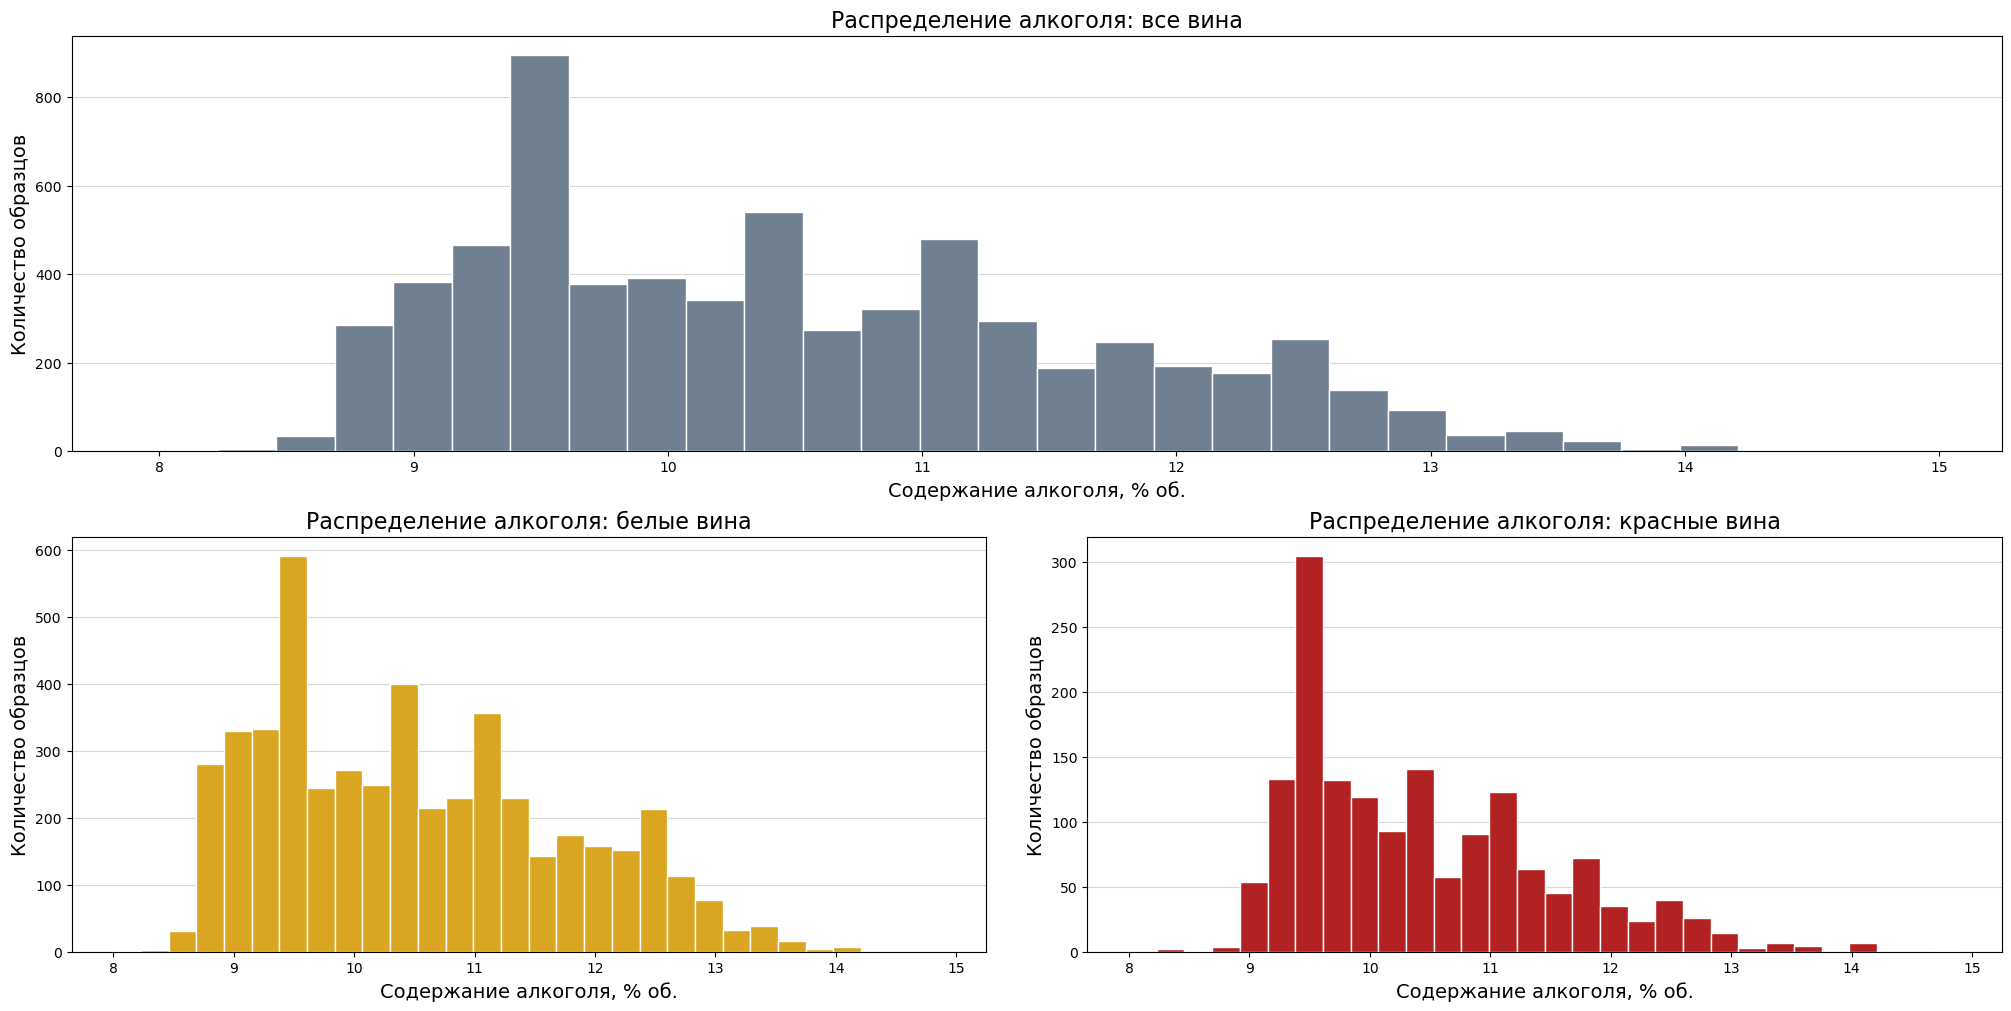

In [30]:

bins = np.linspace(df["Алкоголь"].min(), df["Алкоголь"].max(), 31)

fig = plt.figure(figsize=(20, 10), layout="constrained")
grid = fig.add_gridspec(2, 2)

ax_all = fig.add_subplot(grid[0, :])
ax_white = fig.add_subplot(grid[1, 0], sharex=ax_all)
ax_red = fig.add_subplot(grid[1, 1], sharex=ax_all)

ax_all.hist(df["Алкоголь"], bins=bins, color="slategray", edgecolor="white",)
ax_all.set_title("Распределение алкоголя: все вина", fontsize=16)

ax_white.hist(white_wine["Алкоголь"], bins=bins, color="goldenrod", edgecolor="white",)
ax_white.set_title("Распределение алкоголя: белые вина", fontsize=16)

ax_red.hist(red_wine["Алкоголь"], bins=bins, color="firebrick", edgecolor="white",)
ax_red.set_title("Распределение алкоголя: красные вина", fontsize=16)

for ax in [ax_all, ax_white, ax_red]:
    ax.set_xlabel("Содержание алкоголя, % об.", fontsize=14)
    ax.set_ylabel("Количество образцов", fontsize=14)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.5)

plt.show()

**Гистограмма** показывает частоту попадания значений содержания алкоголя в заданные интервалы.

**Результаты:**
- **Все вина:** наиболее заполненный интервал расположен около 9.5% алкоголя. Основная масса наблюдений находится примерно в диапазоне 9–12%, справа наблюдается хвост более высоких значений.
- **Белые вина:** помимо главного пика около 9.5%, заметная часть наблюдений распределена в области 10–12.5%.
- **Красные вина:** более выражено скопление около 9–10%; с увеличением алкоголя частота в целом снижается.
- Все три распределения визуально имеют правостороннюю асимметрию и не выглядят явно нормальными. Локальные пики могут зависеть от выбора интервалов и округления значений.

Высоты столбиков отражают абсолютное количество образцов, поэтому при разном размере групп для сравнения относительных частот нужна нормировка. Редкие высокие значения сами по себе не являются доказанными выбросами. Гистограмма не позволяет проверить независимость наблюдений или постоянство распределения по порядку записей.

## Построение Normal Probability Plot

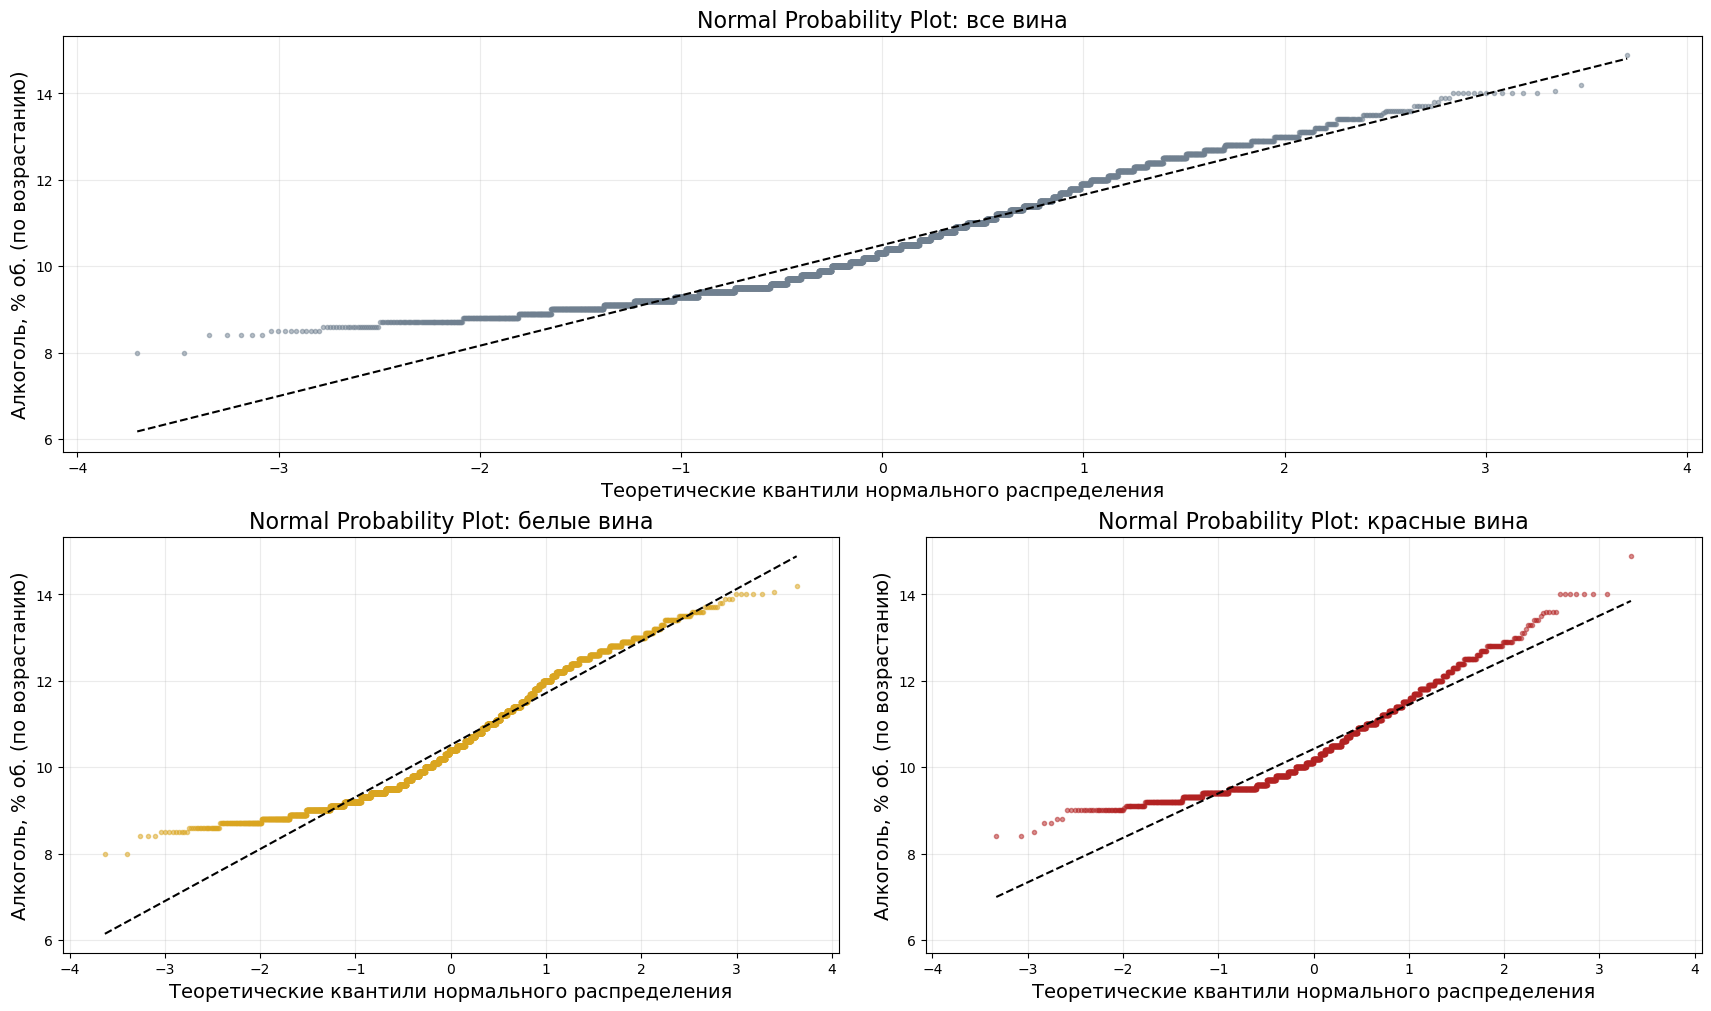

In [31]:
fig = plt.figure(figsize=(17, 10), layout="constrained")
grid = fig.add_gridspec(2, 2)

ax_all = fig.add_subplot(grid[0, :])
ax_white = fig.add_subplot(grid[1, 0], sharex=ax_all, sharey=ax_all)
ax_red = fig.add_subplot(grid[1, 1], sharex=ax_all, sharey=ax_all)

# Все вина
stats.probplot(df["Алкоголь"].dropna(), dist="norm", plot=ax_all,)
ax_all.set_title("Normal Probability Plot: все вина", fontsize=16)

# Белые вина
stats.probplot(white_wine["Алкоголь"].dropna(), dist="norm", plot=ax_white,)
ax_white.set_title("Normal Probability Plot: белые вина", fontsize=16)

# Красные вина
stats.probplot(red_wine["Алкоголь"].dropna(), dist="norm", plot=ax_red,)
ax_red.set_title("Normal Probability Plot: красные вина", fontsize=16)

# Цвета точек и общие настройки
for ax, color in [(ax_all, "slategray"), (ax_white, "goldenrod"),(ax_red, "firebrick")]:
    points, reference_line = ax.get_lines()

    points.set_color(color)
    points.set_markersize(3)
    points.set_alpha(0.5)

    reference_line.set_color("black")
    reference_line.set_linestyle("--")
    reference_line.set_linewidth(1.5)

    ax.set_xlabel("Теоретические квантили нормального распределения", fontsize=14)
    ax.set_ylabel("Алкоголь, % об. (по возрастанию)", fontsize=14)
    ax.grid(alpha=0.25)

plt.show()

**Normal Probability Plot** сопоставляет отсортированные значения алкоголя с теоретическими квантилями нормального распределения. При близости к нормальной форме точки должны располагаться примерно вдоль прямой.

**Результаты:**
- **Все вина:** наблюдается систематический изгиб, особенно заметный в левой части графика.
- **Белые вина:** центральная часть местами близка к прямой, но оба хвоста отклоняются; крайние правые точки находятся ниже линии.
- **Красные вина:** выраженный изгиб и отклонение правых крайних значений выше линии согласуются с правосторонней асимметрией.
- Горизонтальные ступеньки обусловлены повторяющимися значениями и ограниченной точностью записи.

Для всех трёх выборок имеются визуальные свидетельства отклонения от нормального распределения. Это не означает некорректность данных и не запрещает вычислять описательные статистики, но требует осторожности при использовании методов, предполагающих нормальность.

## Интерпретация каждого графика и вывод о выполнении предположений

### Выводы по проверке базовых предположений

Анализ выполнен для признака **«Алкоголь»** по всей выборке и отдельно для белых и красных вин.

| Предположение | График | Результат и вывод |
|---|---|---|
| Случайность и независимость наблюдений | Lag Plot | Сильная связь между соседними значениями визуально не обнаружена. Для красных вин возможна положительная связь. Независимость не подтверждена: отсутствие явного рисунка не является её доказательством. |
| Постоянство положения распределения | Run Sequence Plot | Видны участки с более низкими и более высокими значениями алкоголя, в том числе внутри каждого типа вина. Есть визуальные признаки нарушения постоянства положения. |
| Постоянство вариации | Run Sequence Plot | Из-за плотного наложения наблюдений постоянство разброса однозначно оценить трудно. Для уточнения необходимо сравнение показателей разброса по последовательным блокам. |
| Постоянство формы распределения | Гистограмма совместно с анализом последовательности | Общая гистограмма описывает распределение всей выборки, но не проверяет неизменность его формы между участками. Предположение остаётся непроверенным; требуется сравнение распределений по блокам. |
| Нормальность — дополнительная проверка | Гистограмма и Normal Probability Plot | Наблюдаются правосторонняя асимметрия и систематические отклонения точек от опорной прямой. Для всех трёх выборок имеются визуальные свидетельства отклонения от нормального распределения. |

**Общий вывод.** Совокупность графиков не даёт оснований считать все базовые предположения выполненными. Наиболее заметны неоднородность положения значений по порядку записей и отличие распределения от нормального. Постоянство распределения и его нормальность — разные свойства: распределение может быть постоянным, оставаясь ненормальным.

Порядковый номер образца не обозначает время, поэтому обнаруженные изменения нельзя интерпретировать как временную динамику вина. Они могут отражать группировку или особенности расположения записей. Полученные выводы относятся к содержанию алкоголя и не переносятся автоматически на остальные признаки.

Описательные статистики вычислять можно, однако при дальнейшем анализе следует учитывать тип вина, асимметрию распределения и возможную структуру порядка наблюдений.

### Дополнительная проверка порядка записей
Визуальное отсутствие узкой диагонали на Lag Plot ещё не означает отсутствия связи. Рассчитаем корреляцию с лагом 1 и сравним четыре последовательных блока внутри каждого типа вина. Номер блока отражает положение в файле, а не время.

,Корреляция с лагом 1
Все вина,0.250
Белые вина,0.247
Красные вина,0.256


,Группа,Блок,N,Среднее,Медиана,Ст. откл.,IQR
0,Белые вина,1,1225,10.176,10.0,1.075,1.5
1,Белые вина,2,1225,10.289,10.1,1.131,1.6
2,Белые вина,3,1224,10.847,10.8,1.276,2.2
3,Белые вина,4,1224,10.746,10.7,1.292,2.1
4,Красные вина,1,400,10.000,9.7,0.930,1.0
5,Красные вина,2,400,10.196,9.9,1.019,1.3
6,Красные вина,3,400,10.950,10.9,1.083,1.8
7,Красные вина,4,399,10.545,10.4,0.974,1.4


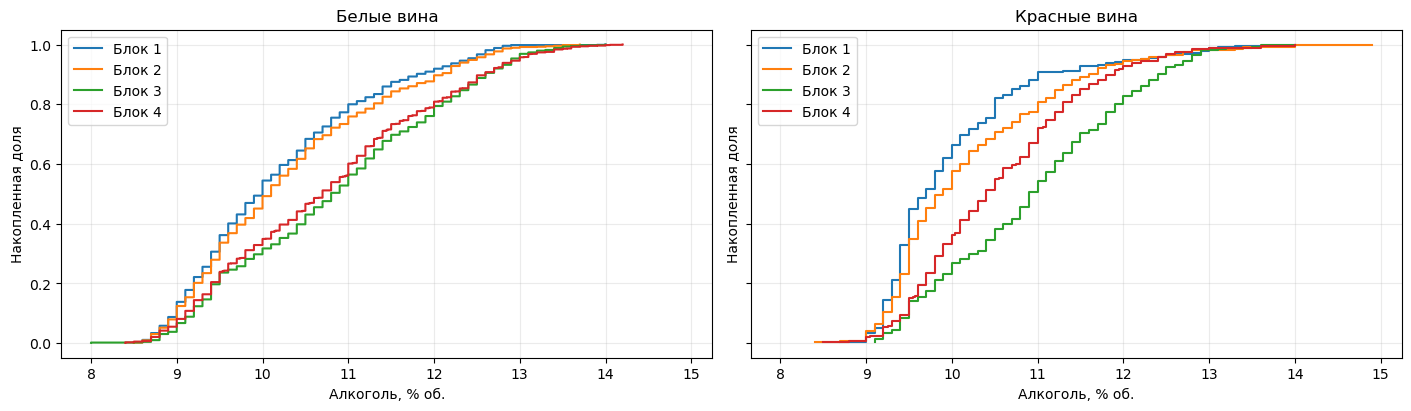

In [32]:
groups = {"Все вина": df, "Белые вина": white_wine, "Красные вина": red_wine}
lag_correlation = pd.Series({name: data["Алкоголь"].autocorr(lag=1) for name, data in groups.items()}, name="Корреляция с лагом 1")
display(lag_correlation.round(3).to_frame())
block_results = []
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained", sharex=True, sharey=True)
for ax, (name, data) in zip(axes, [("Белые вина", white_wine), ("Красные вина", red_wine)]):
    for number, values in enumerate(np.array_split(data["Алкоголь"].to_numpy(), 4), start=1):
        s = pd.Series(values)
        block_results.append({"Группа": name, "Блок": number, "N": len(s), "Среднее": s.mean(), "Медиана": s.median(), "Ст. откл.": s.std(), "IQR": s.quantile(.75) - s.quantile(.25)})
        x = np.sort(values)
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", label=f"Блок {number}")
    ax.set_title(name)
    ax.set_xlabel("Алкоголь, % об.")
    ax.set_ylabel("Накопленная доля")
    ax.grid(alpha=.25)
    ax.legend()
display(pd.DataFrame(block_results).round(3))
plt.show()

Корреляция соседних значений составляет около 0.25 во всех трёх выборках: положительная связь присутствует и у белых, и у красных вин. Поэтому первоначальный визуальный вывод уточняется: порядок записей нельзя считать заведомо случайным. Таблица блоков и их накопленные распределения позволяют оценить различия положения и разброса без смешивания типов. У белых вин среднее по блокам меняется от 10.176 до 10.847% об., стандартное отклонение — от 1.075 до 1.292 п.п. У красных среднее меняется от 10.000 до 10.950% об. Кривые ECDF блоков различаются, поэтому одинаковость распределений по всей последовательности не следует принимать без оговорок. Это описательная диагностика порядка, а не доказательство временного изменения процесса.

# Часть 3: Описательная статистика

## Расчёт мер центральной тенденции: среднее, медиана, мода


In [33]:
central_tendency = pd.DataFrame({
    "Все вина": {
        "Среднее": df["Алкоголь"].mean(),
        "Медиана": df["Алкоголь"].median(),
        "Мода": df["Алкоголь"].mode().tolist()
    },
    "Белые вина": {
        "Среднее": white_wine["Алкоголь"].mean(),
        "Медиана": white_wine["Алкоголь"].median(),
        "Мода": white_wine["Алкоголь"].mode().tolist()
    },
    "Красные вина": {
        "Среднее": red_wine["Алкоголь"].mean(),
        "Медиана": red_wine["Алкоголь"].median(),
        "Мода": red_wine["Алкоголь"].mode().tolist()
    }
})

central_tendency

,Все вина,Белые вина,Красные вина
Среднее,10.491801,10.514267,10.422983
Медиана,10.3,10.4,10.2
Мода,[9.5],[9.4],[9.5]


## Расчёт мер разброса: дисперсия, стандартное отклонение, IQR, MAD, размах, коэффициент вариации

In [34]:
groups = {"Все вина": df, "Белые вина": white_wine, "Красные вина": red_wine}
results = {}

for name, data in groups.items():
    alcohol = data["Алкоголь"].dropna()
    mean = alcohol.mean()
    median = alcohol.median()
    std = alcohol.std(ddof=1)
    q1 = alcohol.quantile(0.25)
    q3 = alcohol.quantile(0.75)

    results[name] = {
        "Дисперсия, (п.п.)²": alcohol.var(ddof=1),
        "Стандартное отклонение, п.п.": std,
        "IQR, п.п.": q3 - q1,
        "MAD, п.п.": (alcohol - median).abs().median(),
        "Размах, п.п.": alcohol.max() - alcohol.min(),
        "Коэффициент вариации, %": std / mean * 100 if mean != 0 else float("nan")
    }

dispersion = pd.DataFrame(results)
dispersion.round(3)

,Все вина,Белые вина,Красные вина
"Дисперсия, (п.п.)²",1.423,1.514,1.136
"Стандартное отклонение, п.п.",1.193,1.231,1.066
"IQR, п.п.",1.800,1.900,1.600
"MAD, п.п.",0.900,1.000,0.700
"Размах, п.п.",6.900,6.200,6.500
"Коэффициент вариации, %",11.368,11.704,10.224


## Сравнение среднего и медианы
Для всех трёх выборок сравним среднее, медиану и выборочный коэффициент асимметрии. Разница среднего и медианы сама по себе не определяет форму распределения, поэтому учитываем также гистограммы и вероятностные графики.

In [35]:
comparison = pd.DataFrame({name: {"Среднее": data["Алкоголь"].mean(), "Медиана": data["Алкоголь"].median(), "Среднее − медиана": data["Алкоголь"].mean() - data["Алкоголь"].median(), "Асимметрия": data["Алкоголь"].skew()} for name, data in groups.items()}).T
comparison.round(3)

,Среднее,Медиана,Среднее − медиана,Асимметрия
Все вина,10.492,10.3,0.192,0.566
Белые вина,10.514,10.4,0.114,0.487
Красные вина,10.423,10.2,0.223,0.861


В общей выборке среднее содержание алкоголя — 10.492% об., медиана — 10.3% об. У белых вин эти показатели равны 10.514 и 10.4, у красных — 10.423 и 10.2. Среднее выше медианы во всех группах, коэффициент асимметрии положительный. Вместе с графиками это указывает на правостороннюю асимметрию, более выраженную у красных вин.

Стандартное отклонение алкоголя у белых вин составляет 1.231 п.п., у красных — 1.066 п.п. IQR равен 1.9 и 1.6 п.п. соответственно. Таким образом, у белых вин центральная часть распределения шире, хотя максимальная крепость выше у красных. Размах и типичный разброс описывают разные свойства.

## Сводная статистика физико-химических признаков
Для полноты рассчитаем показатели по всем 11 измеряемым признакам. Качество и тип вина приведены отдельно. Коэффициент вариации для pH не рассчитывается, так как отношения значений логарифмической шкалы не имеют нужного смысла. Моды относятся к записанным значениям и зависят от точности измерений.

In [36]:
numeric_features = [column for column in df.select_dtypes(include="number").columns if column != "Качество"]
summary_rows = []
for column in numeric_features:
    x = df[column].dropna()
    summary_rows.append({"Признак": column, "Среднее": x.mean(), "Медиана": x.median(), "Мода": x.mode().tolist(), "Дисперсия": x.var(ddof=1), "Ст. откл.": x.std(ddof=1), "IQR": x.quantile(.75) - x.quantile(.25), "MAD": (x - x.median()).abs().median(), "Размах": x.max() - x.min(), "CV, %": x.std() / x.mean() * 100 if column != "pH" and x.mean() != 0 else np.nan})
summary = pd.DataFrame(summary_rows).set_index("Признак")
display(summary.round(6))
display(df["Качество"].value_counts().sort_index().rename("Количество").to_frame())
print("Медиана качества:", df["Качество"].median(), "; мода:", df["Качество"].mode().tolist())
display(df["Тип вина"].value_counts(normalize=True).mul(100).round(2).rename("Доля, %").to_frame())

,Среднее,Медиана,Мода,Дисперсия,Ст. откл.,IQR,MAD,Размах,"CV, %"
Признак,,,,,,,,,
Нелетучая кислотность,7.215307,7.00000,[6.8],1.680740,1.296434,1.30000,0.60000,12.10000,17.967825
Летучая кислотность,0.339666,0.29000,[0.28],0.027105,0.164636,0.17000,0.08000,1.50000,48.470107
Лимонная кислота,0.318633,0.31000,[0.3],0.021117,0.145318,0.14000,0.07000,1.66000,45.606628
Остаточный сахар,5.443235,3.00000,[2.0],22.636696,4.757804,6.30000,1.70000,65.20000,87.407644
Хлориды,0.056034,0.04700,[0.044],0.001227,0.035034,0.02700,0.01100,0.60200,62.522197
Свободный диоксид серы,30.525319,29.00000,[29.0],315.041192,17.749400,24.00000,12.00000,288.00000,58.146483
Общий диоксид серы,115.744574,118.00000,[111.0],3194.720039,56.521855,79.00000,39.00000,434.00000,48.833265
Плотность,0.994697,0.99489,"[0.9972, 0.9976]",0.000009,0.002999,0.00465,0.00231,0.05187,0.301466
pH,3.218501,3.21000,[3.16],0.025853,0.160787,0.21000,0.11000,1.29000,NaN


,Количество
Качество,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


Медиана качества: 6.0 ; мода: [6]


,"Доля, %"
Тип вина,
white,75.39
red,24.61


# Часть 4: Визуализация распределения
## Гистограммы с разным числом интервалов
Сравним 10, 20 и 40 интервалов на одном и том же диапазоне алкоголя. Малое число интервалов сглаживает детали, большое сильнее проявляет округление и локальные пики.

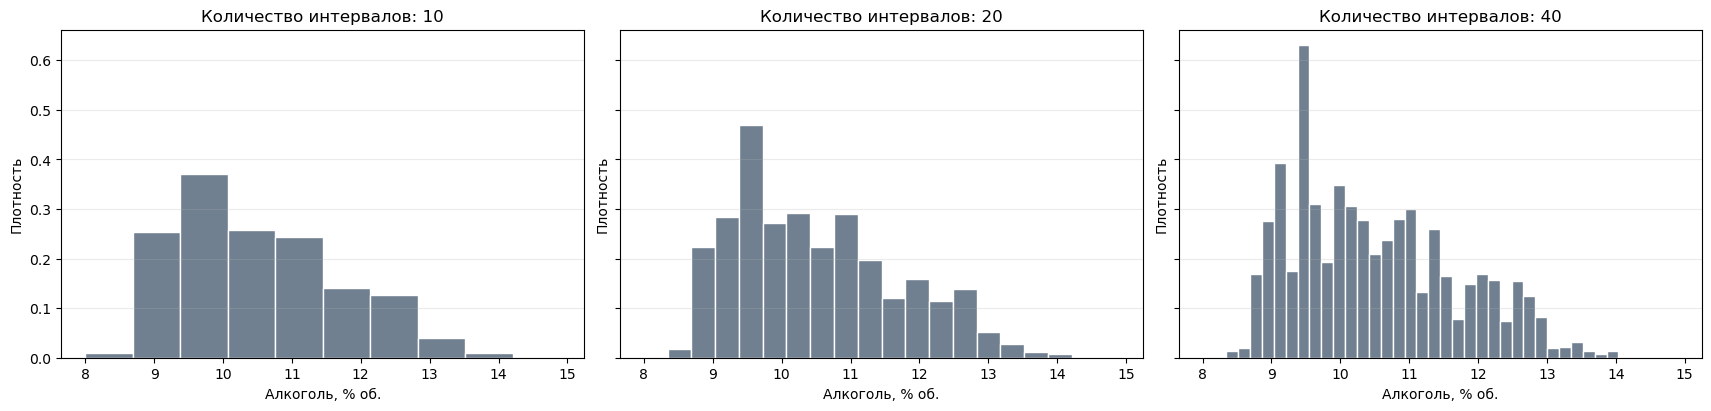

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4), layout="constrained", sharex=True, sharey=True)
for ax, count in zip(axes, [10, 20, 40]):
    edges = np.linspace(df["Алкоголь"].min(), df["Алкоголь"].max(), count + 1)
    ax.hist(df["Алкоголь"], bins=edges, density=True, color="slategray", edgecolor="white")
    ax.set_title(f"Количество интервалов: {count}")
    ax.set_xlabel("Алкоголь, % об.")
    ax.set_ylabel("Плотность")
    ax.grid(axis="y", alpha=.25)
plt.show()

При изменении числа интервалов сохраняется общий правый хвост, но меняются высота и число локальных пиков. Поэтому вывод о нескольких отдельных распределениях нельзя делать только по одному варианту гистограммы. Здесь используется плотность: площадь всех столбиков равна единице.

## Box Plot и правило 1.5 · IQR
Ящик охватывает центральные 50% значений, линия внутри — медиана. Усы доходят до крайних наблюдений внутри границ Q1 − 1.5 · IQR и Q3 + 1.5 · IQR. Точки за границами отмечаются как потенциальные выбросы, но не удаляются автоматически.

,Q1,Q3,Нижняя граница,Верхняя граница,Число выбросов,"Доля, %"
Группа,,,,,,
Все вина,9.5,11.3,6.80,14.00,3,0.046
Белые вина,9.5,11.4,6.65,14.25,0,0.000
Красные вина,9.5,11.1,7.10,13.50,13,0.813


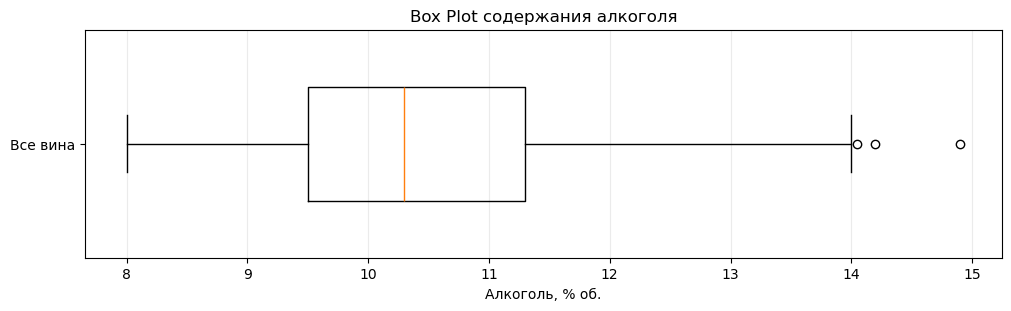

,Алкоголь,Качество,Тип вина
652,14.90,5,red
5517,14.20,7,white
6102,14.05,7,white


In [38]:
outlier_rows = []
outlier_masks = {}
for name, data in groups.items():
    x = data["Алкоголь"]
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (x < lower) | (x > upper)
    outlier_masks[name] = mask
    outlier_rows.append({"Группа": name, "Q1": q1, "Q3": q3, "Нижняя граница": lower, "Верхняя граница": upper, "Число выбросов": int(mask.sum()), "Доля, %": mask.mean() * 100})
outlier_summary = pd.DataFrame(outlier_rows).set_index("Группа")
display(outlier_summary.round(3))
fig, ax = plt.subplots(figsize=(10, 3), layout="constrained")
ax.boxplot(df["Алкоголь"], vert=False, widths=.5)
ax.set_yticks([1], ["Все вина"])
ax.set_xlabel("Алкоголь, % об.")
ax.set_title("Box Plot содержания алкоголя")
ax.grid(axis="x", alpha=.25)
plt.show()
display(df.loc[outlier_masks["Все вина"], ["Алкоголь", "Качество", "Тип вина"]])

Для всей выборки верхняя граница равна 14% об., отмечены 3 наблюдения. При отдельных границах для красных вин отмечаются 13 наблюдений, для белых — 0. Различие объясняется разными квартилями и IQR. Оно показывает, почему необычность значения нужно оценивать относительно выбранной группы.

## Эмпирическая функция распределения и процентили
Теоретическая CDF имеет вид F(x) = P(X ≤ x). По наблюдениям строится ECDF: доля образцов с алкоголем не выше x. Кривая позволяет читать накопленные доли без выбора интервалов.

,"Алкоголь, % об."
P10,9.1
P25,9.5
P50,10.3
P75,11.3
P90,12.3
P95,12.7


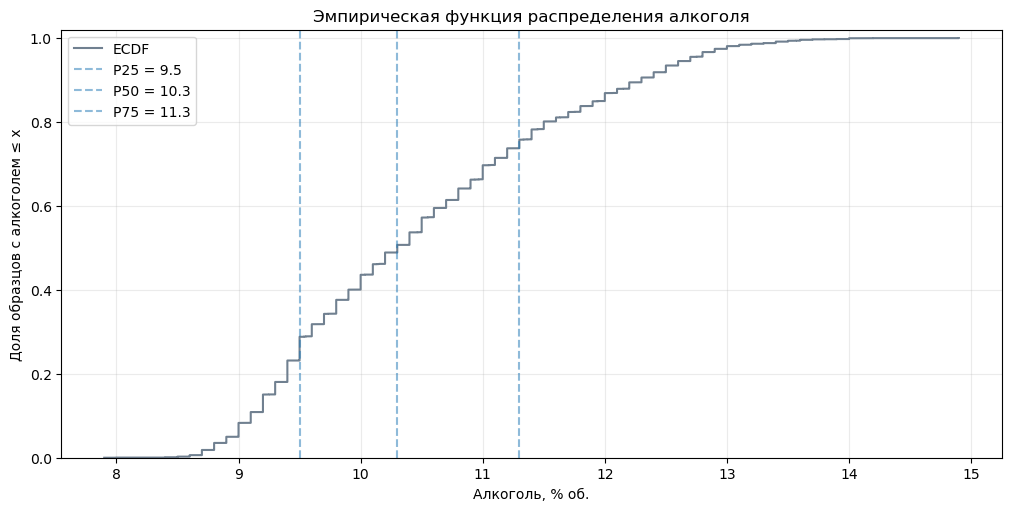

Доля вин с алкоголем не выше 12% об.: 86.89%


In [39]:
alcohol_sorted = np.sort(df["Алкоголь"].dropna().to_numpy())
ecdf_y = np.arange(1, len(alcohol_sorted) + 1) / len(alcohol_sorted)
percentiles = df["Алкоголь"].quantile([.1, .25, .5, .75, .9, .95]).rename("Алкоголь, % об.").to_frame()
percentiles.index = ["P10", "P25", "P50", "P75", "P90", "P95"]
display(percentiles)
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.step(np.r_[alcohol_sorted[0] - .1, alcohol_sorted], np.r_[0, ecdf_y], where="post", color="slategray", label="ECDF")
for probability in [.25, .5, .75]:
    value = df["Алкоголь"].quantile(probability)
    ax.axvline(value, linestyle="--", alpha=.5, label=f"P{int(probability * 100)} = {value:.1f}")
ax.set_xlabel("Алкоголь, % об.")
ax.set_ylabel("Доля образцов с алкоголем ≤ x")
ax.set_ylim(0, 1.02)
ax.set_title("Эмпирическая функция распределения алкоголя")
ax.grid(alpha=.25)
ax.legend()
plt.show()
print(f"Доля вин с алкоголем не выше 12% об.: {(df['Алкоголь'] <= 12).mean():.2%}")

Медиана равна 10.3% об., первый и третий квартили — 9.5 и 11.3% об. P90 равен 12.3% об., P95 — 12.7% об. Из-за повторяющихся значений доля наблюдений, не превышающих квантиль, может быть больше номинальных 25%, 50% или 90%. Точная доля для заданного порога рассчитывается непосредственно по данным.

## KDE и сравнение с гистограммой
KDE — сглаженная оценка плотности. Параметр ширины окна регулирует сглаживание. Сравним стандартное окно Скотта с половинным и двойным. Гистограмма нормирована, поэтому её высоты и KDE выражены в одном масштабе.

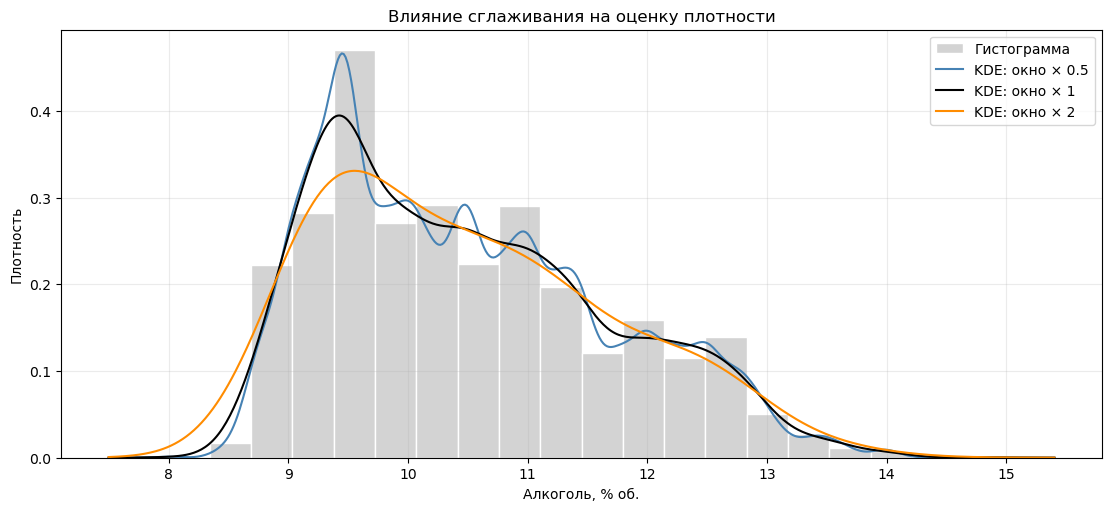

In [40]:
x = df["Алкоголь"].dropna().to_numpy()
kde = stats.gaussian_kde(x)
x_grid = np.linspace(x.min() - .5, x.max() + .5, 500)
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
ax.hist(x, bins=20, density=True, color="lightgray", edgecolor="white", label="Гистограмма")
for factor, color in [(.5, "steelblue"), (1, "black"), (2, "darkorange")]:
    estimate = stats.gaussian_kde(x, bw_method=kde.factor * factor)
    ax.plot(x_grid, estimate(x_grid), color=color, label=f"KDE: окно × {factor}")
ax.set_xlabel("Алкоголь, % об.")
ax.set_ylabel("Плотность")
ax.set_title("Влияние сглаживания на оценку плотности")
ax.legend()
ax.grid(alpha=.25)
plt.show()

KDE сохраняет основное скопление около невысоких значений алкоголя и правый хвост. Малое окно подчёркивает локальные неровности, большое объединяет их. Гауссовская KDE может продолжаться за минимальное и максимальное наблюдаемые значения: это свойство сглаживания, а не наличие дополнительных образцов.

# Часть 5: Анализ взаимосвязей
## Диаграммы рассеяния с линиями регрессии
Рассмотрим связи алкоголя с плотностью, остаточного сахара с плотностью и алкоголя с качеством. Линия показывает линейную тенденцию, но не доказывает причинность. Для качества числовой анализ условно предполагает сопоставимые интервалы между баллами.

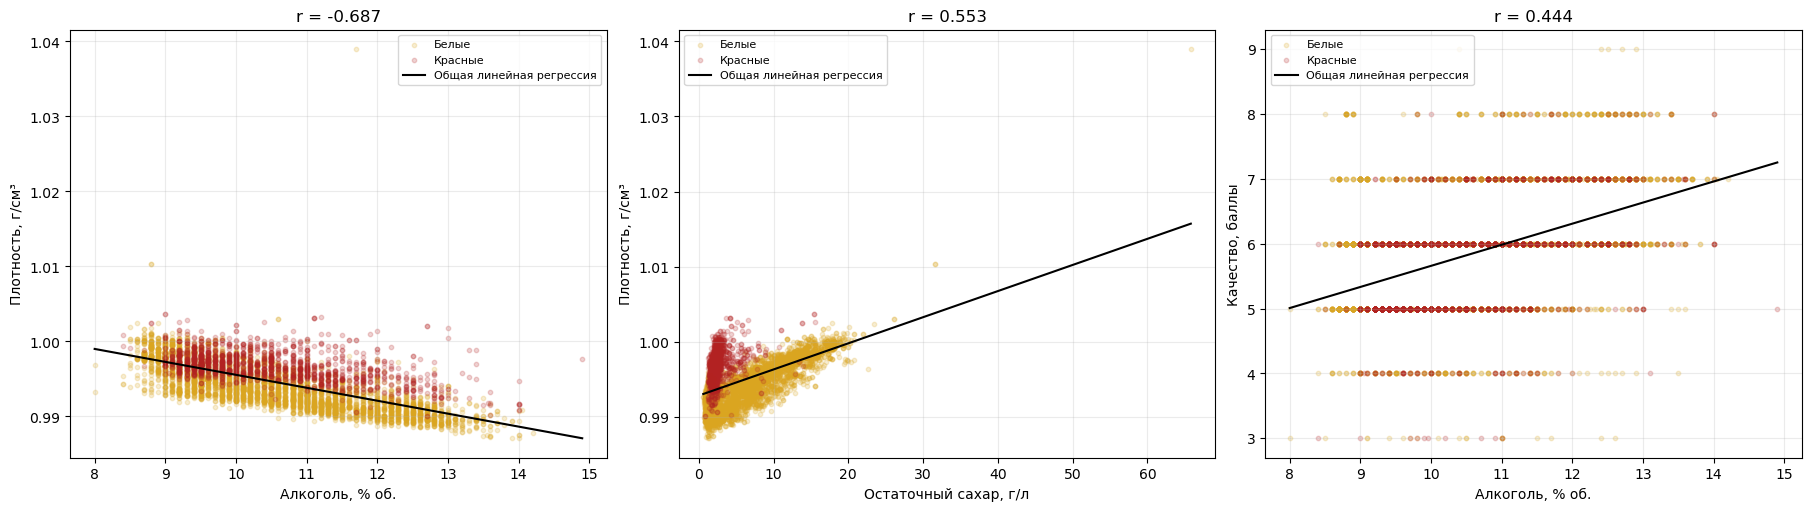

In [41]:
pairs = [("Алкоголь", "Плотность"), ("Остаточный сахар", "Плотность"), ("Алкоголь", "Качество")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")
for ax, (x_col, y_col) in zip(axes, pairs):
    for label, data, color in [("Белые", white_wine, "goldenrod"), ("Красные", red_wine, "firebrick")]:
        ax.scatter(data[x_col], data[y_col], s=10, alpha=.2, color=color, label=label)
    fit = stats.linregress(df[x_col], df[y_col])
    line_x = np.linspace(df[x_col].min(), df[x_col].max(), 100)
    ax.plot(line_x, fit.intercept + fit.slope * line_x, color="black", label="Общая линейная регрессия")
    axis_labels = {"Алкоголь": "Алкоголь, % об.", "Плотность": "Плотность, г/см³", "Остаточный сахар": "Остаточный сахар, г/л", "Качество": "Качество, баллы"}
    ax.set_xlabel(axis_labels[x_col])
    ax.set_ylabel(axis_labels[y_col])
    ax.set_title(f"r = {fit.rvalue:.3f}")
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
plt.show()

## Ковариация и корреляция Пирсона
Ковариация зависит от единиц измерения, поэтому её величины для разных пар напрямую не сравниваются. Корреляция Пирсона лежит от −1 до 1 и описывает линейную связь. Для всех пар дополнительно приведены корреляции внутри каждого типа вина.

,Ковариация,Пирсон: все,Пирсон: белые,Пирсон: красные
Пара,,,,
Алкоголь — Плотность,-0.0025,-0.6867,-0.7801,-0.4962
Остаточный сахар — Плотность,0.0079,0.5525,0.8390,0.3553
Алкоголь — Качество,0.4628,0.4443,0.4356,0.4762


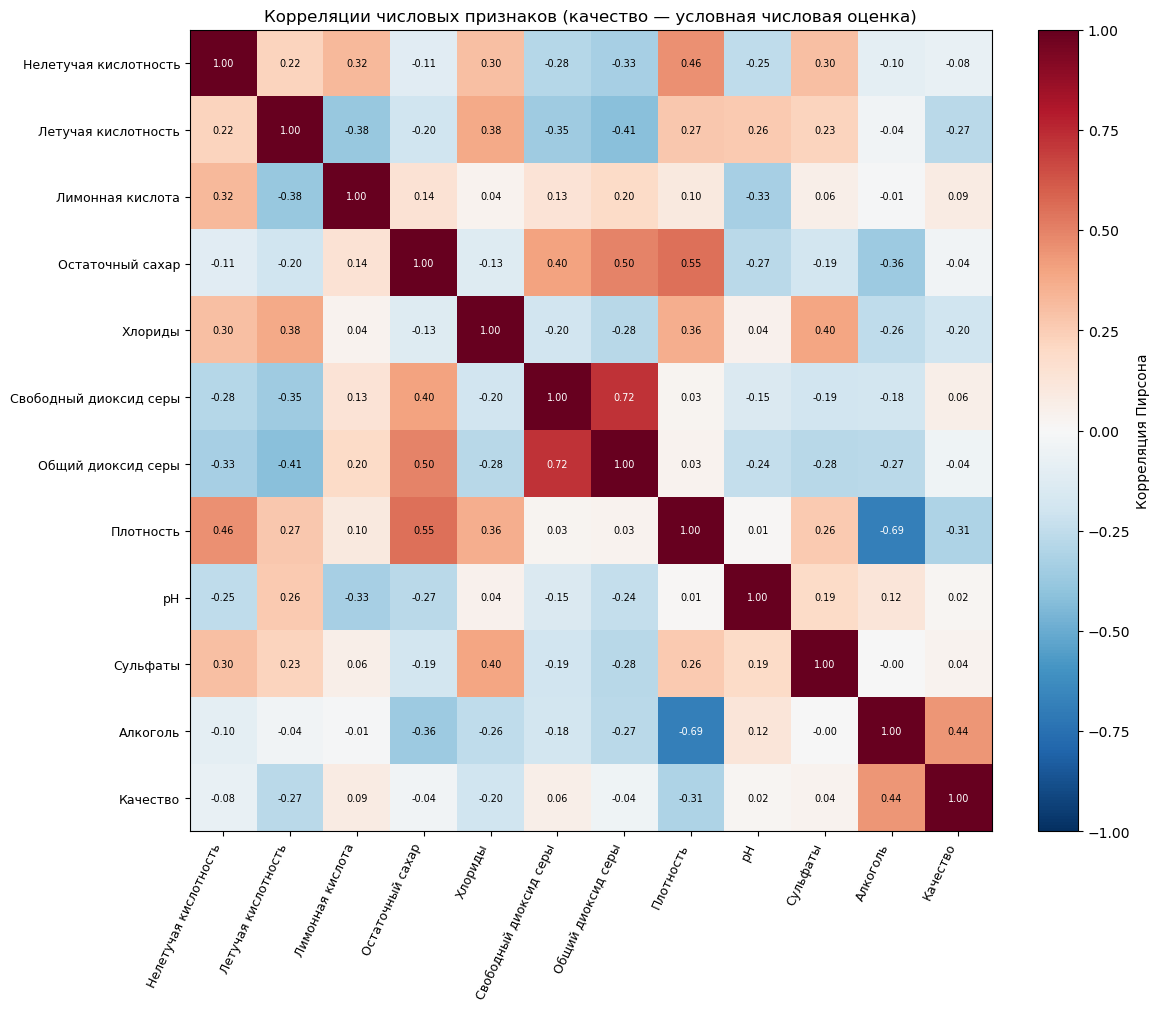

Спирмен: алкоголь и качество = 0.447


In [42]:
pair_rows = []
for x_col, y_col in pairs:
    pair_rows.append({"Пара": f"{x_col} — {y_col}", "Ковариация": df[[x_col, y_col]].cov().iloc[0, 1], "Пирсон: все": df[x_col].corr(df[y_col]), "Пирсон: белые": white_wine[x_col].corr(white_wine[y_col]), "Пирсон: красные": red_wine[x_col].corr(red_wine[y_col])})
pair_stats = pd.DataFrame(pair_rows).set_index("Пара")
display(pair_stats.round(4))
correlation = df.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=65, ha="right", fontsize=9)
ax.set_yticks(range(len(correlation)), correlation.columns, fontsize=9)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(correlation.iloc[i, j]) > .65 else "black")
fig.colorbar(image, ax=ax, label="Корреляция Пирсона")
ax.set_title("Корреляции числовых признаков (качество — условная числовая оценка)")
plt.show()
print("Спирмен: алкоголь и качество =", round(df["Алкоголь"].corr(df["Качество"], method="spearman"), 3))

Алкоголь положительно связан с оценкой качества: r ≈ 0.444 во всей выборке, 0.436 у белых и 0.476 у красных вин. Связь сохраняется внутри обоих типов, но алкоголь не определяет оценку однозначно. Плотность отрицательно связана с алкоголем и положительно — с остаточным сахаром. Это физически объяснимые направления, однако величины общей и внутригрупповой корреляций могут отличаться. Ранговая корреляция Спирмена дополняет условное применение Пирсона к порядковому качеству.

## Матрица диаграмм рассеяния
Для читаемости выбраны четыре признака: алкоголь, плотность, остаточный сахар и летучая кислотность. На диагонали — гистограммы, вне диагонали — попарные связи. Используются все строки.

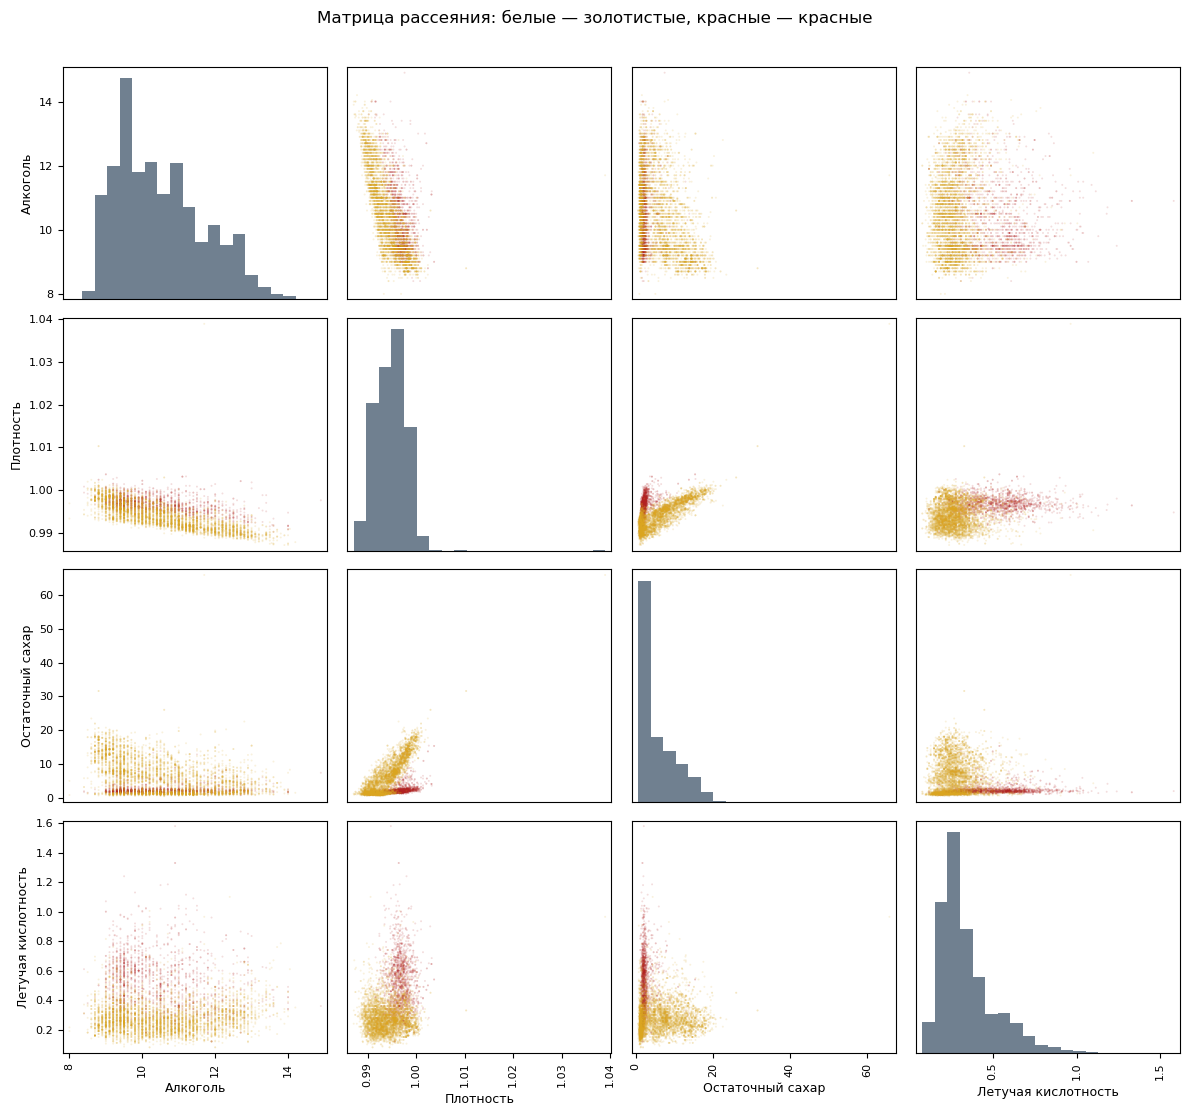

In [43]:
from pandas.plotting import scatter_matrix
matrix_features = ["Алкоголь", "Плотность", "Остаточный сахар", "Летучая кислотность"]
point_colors = df["Тип вина"].map({"white": "goldenrod", "red": "firebrick"})
axes = scatter_matrix(df[matrix_features], figsize=(12, 11), diagonal="hist", color=point_colors, alpha=.15, s=8, hist_kwds={"bins": 20, "color": "slategray"})
for ax in axes.ravel():
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)
plt.suptitle("Матрица рассеяния: белые — золотистые, красные — красные", y=1.01)
plt.tight_layout()
plt.show()

Матрица позволяет одновременно увидеть асимметрию отдельных признаков, направления связей и различия типов вина. Скопления разных цветов напоминают, что общая линейная связь может частично отражать смешение групп. Для остаточного сахара видны редкие большие значения, поэтому далее проверяется чувствительность корреляций к крайним наблюдениям.

## Влияние выбросов и повторов на корреляцию
Для каждой пары границы 1.5 · IQR рассчитываются по физико-химическим признакам отдельно внутри белых и красных вин. Строка временно исключается из сравнения, если хотя бы один из этих признаков выходит за свои границы. Качество не фильтруется как непрерывная величина. Это анализ чувствительности, а не окончательная очистка данных.

In [44]:
sensitivity_rows = []
for x_col, y_col in pairs:
    keep = pd.Series(True, index=df.index)
    for wine_type, part in df.groupby("Тип вина"):
        for column in [x_col, y_col]:
            if column == "Качество":
                continue
            q1, q3 = part[column].quantile([.25, .75])
            iqr = q3 - q1
            keep.loc[part.index] &= part[column].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    before = df[x_col].corr(df[y_col])
    after = df.loc[keep, x_col].corr(df.loc[keep, y_col])
    unique = df.drop_duplicates()
    sensitivity_rows.append({"Пара": f"{x_col} — {y_col}", "N исходное": len(df), "N после IQR": int(keep.sum()), "r исходное": before, "r после IQR": after, "Изменение r": after - before, "r без полных повторов": unique[x_col].corr(unique[y_col])})
sensitivity = pd.DataFrame(sensitivity_rows).set_index("Пара")
display(sensitivity.round(4))
for pair, row in sensitivity.iterrows():
    print(f"{pair}: исключено {int(row['N исходное'] - row['N после IQR'])} строк; r меняется с {row['r исходное']:.3f} до {row['r после IQR']:.3f}.")

,N исходное,N после IQR,r исходное,r после IQR,Изменение r,r без полных повторов
Пара,,,,,,
Алкоголь — Плотность,6497,6444,-0.6867,-0.7135,-0.0267,-0.6678
Остаточный сахар — Плотность,6497,6312,0.5525,0.5429,-0.0096,0.5209
Алкоголь — Качество,6497,6484,0.4443,0.4438,-0.0005,0.4694


Алкоголь — Плотность: исключено 53 строк; r меняется с -0.687 до -0.713.
Остаточный сахар — Плотность: исключено 185 строк; r меняется с 0.553 до 0.543.
Алкоголь — Качество: исключено 13 строк; r меняется с 0.444 до 0.444.


После фильтрации корреляция алкоголя с плотностью меняется с −0.687 до −0.713, сахара с плотностью — с 0.553 до 0.543, алкоголя с качеством — с 0.4443 до 0.4438. Направления связей сохраняются; связь алкоголя с качеством практически не меняется. После удаления полных повторов последняя корреляция равна 0.469. Таблица показывает, насколько вывод о линейной связи зависит от выбранного правила фильтрации. Удаление крайних значений меняет состав выборки и не обязано улучшать анализ. Аналогично полные повторы могут влиять на веса разных сочетаний признаков. Основные результаты сохраняются на исходных данных; отфильтрованные варианты используются только для сопоставления.

**Гипотезы для дальнейшего исследования:**
1. Внутри каждого типа более высокому алкоголю в среднем соответствует более высокая оценка качества. Проверять с учётом кислотности и других признаков.
2. При одинаковом содержании сахара увеличение алкоголя связано со снижением плотности. Для проверки нужна многомерная модель.
3. Остаточный сахар связан с плотностью, причём характер связи может различаться у белых и красных вин.
4. Повышенная летучая кислотность связана со снижением качества, но сила связи может зависеть от типа вина.

Эти гипотезы сформулированы после просмотра данных и требуют отдельной проверки. Корреляция не доказывает причинность.

# Часть 6: Сравнительный анализ
Категориальный признак — **тип вина**, количественный — **алкоголь**. Сопоставим медианы, разброс и накопленные доли. В отличие от абсолютных частот, ECDF позволяет сравнивать группы разного размера.

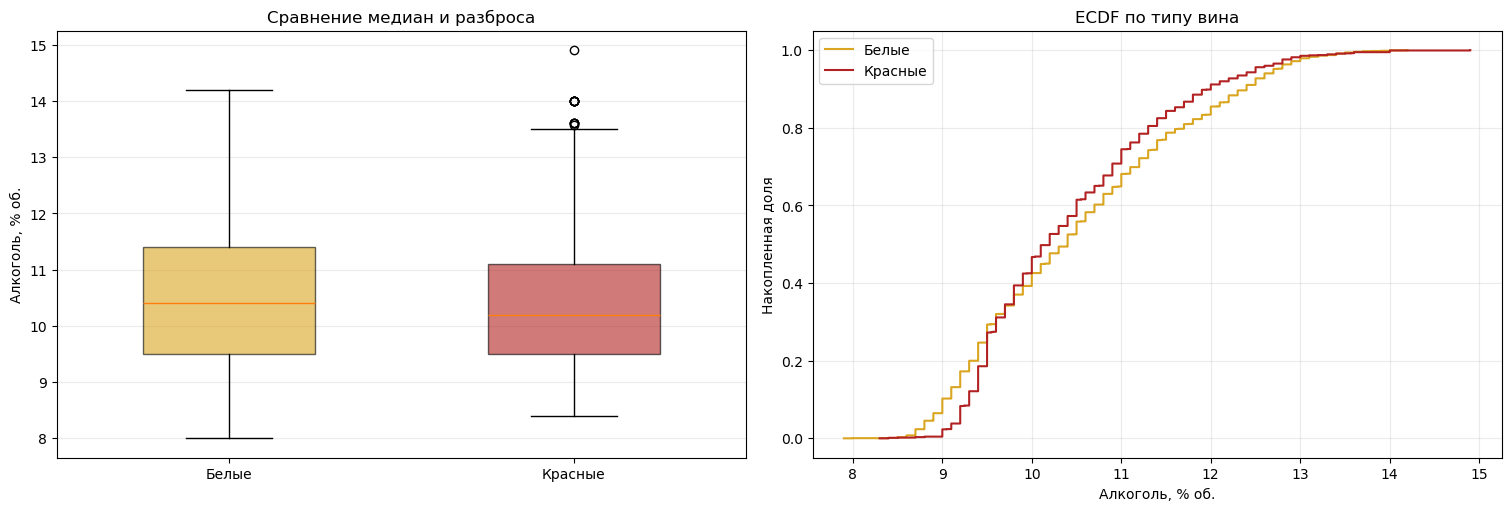

,N,Среднее,Медиана,Стандартное_отклонение,Минимум,Максимум,IQR,"Доля алкоголя ≤ 10%, %"
Тип вина,,,,,,,,
red,1599,10.423,10.2,1.066,8.4,14.9,1.6,46.717
white,4898,10.514,10.4,1.231,8.0,14.2,1.9,42.568


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
box = axes[0].boxplot([white_wine["Алкоголь"], red_wine["Алкоголь"]], patch_artist=True, widths=.5)
for patch, color in zip(box["boxes"], ["goldenrod", "firebrick"]):
    patch.set_facecolor(color)
    patch.set_alpha(.6)
axes[0].set_xticks([1, 2], ["Белые", "Красные"])
axes[0].set_ylabel("Алкоголь, % об.")
axes[0].set_title("Сравнение медиан и разброса")
axes[0].grid(axis="y", alpha=.25)
for label, data, color in [("Белые", white_wine, "goldenrod"), ("Красные", red_wine, "firebrick")]:
    values = np.sort(data["Алкоголь"].to_numpy())
    axes[1].step(np.r_[values[0] - .1, values], np.r_[0, np.arange(1, len(values) + 1) / len(values)], where="post", label=label, color=color)
axes[1].set_xlabel("Алкоголь, % об.")
axes[1].set_ylabel("Накопленная доля")
axes[1].set_title("ECDF по типу вина")
axes[1].legend()
axes[1].grid(alpha=.25)
plt.show()
group_comparison = df.groupby("Тип вина")["Алкоголь"].agg(N="count", Среднее="mean", Медиана="median", Стандартное_отклонение="std", Минимум="min", Максимум="max")
group_comparison["IQR"] = df.groupby("Тип вина")["Алкоголь"].quantile(.75) - df.groupby("Тип вина")["Алкоголь"].quantile(.25)
group_comparison["Доля алкоголя ≤ 10%, %"] = df.groupby("Тип вина")["Алкоголь"].apply(lambda x: (x <= 10).mean() * 100)
display(group_comparison.round(3))

Медиана алкоголя у белых вин равна 10.4% об., у красных — 10.2% об.: разница 0.2 п.п. Разница средних меньше — около 0.091 п.п. У белых вин выше стандартное отклонение и IQR, то есть их центральное распределение шире. При этом максимум у красных выше (14.9 против 14.2% об.).

Распределения сильно перекрываются: по одному алкоголю нельзя надёжно определить тип вина. Накопленные кривые не дают оснований утверждать строгое превосходство одной группы по всем значениям. Это описательные различия данной выборки; статистическая значимость и перенос на другие вина здесь не проверялись.

# Часть 7: Итоговый отчёт и выводы

1. Исследован Wine Quality: 6497 образцов, 13 столбцов, 1599 красных и 4898 белых вин. Пропусков не обнаружено. Найдено 1177 полных повторов сверх первого вхождения; они сохранены, а влияние их исключения на корреляции проверено отдельно.
2. Основной одномерный анализ выполнен для алкоголя. Среднее по всей выборке равно 10.492% об., медиана — 10.3% об. Среднее выше медианы, гистограмма имеет правый хвост, Normal Probability Plot отклоняется от прямой. Это согласуется с положительной асимметрией.
3. Порядок записей неоднороден: на Run Sequence Plot видны участки с разным уровнем, корреляция с лагом 1 около 0.25. Отсутствие времени, номера партии и идентификатора производителя ограничивает объяснение этой структуры.
4. По общему правилу 1.5 · IQR для алкоголя отмечены 3 потенциальных выброса. При расчёте внутри типов — 13 у красных вин и 0 у белых. Такие значения не признаны ошибками автоматически.
5. Для распределения построены гистограммы с разным числом интервалов, Box Plot, ECDF и KDE. Границы бинов и ширина окна меняют детали изображения, но не отменяют общей асимметрии. Центральные 50% значений алкоголя в общей выборке находятся между 9.5 и 11.3% об.
6. Алкоголь положительно связан с оценкой качества (Пирсон около 0.444), плотность отрицательно связана с алкоголем и положительно — с сахаром. Сила связей рассмотрена отдельно по типам и после временного исключения потенциальных выбросов. Причинные выводы по этим результатам не делаются.
7. У белых вин немного выше медиана алкоголя и шире центральный разброс. Различия не устраняют сильное перекрытие групп.

**Применимость моделей.** Данные подходят для дальнейшего изучения качества по физико-химическим признакам. Линейную регрессию можно использовать как базовый вариант при условной числовой трактовке баллов; альтернативой является порядковая модель. Ненормальность исходного алкоголя сама по себе не запрещает регрессию: предположения проверяются для ошибок построенной модели. Плотность, сахар и алкоголь связаны между собой, поэтому нужно учитывать мультиколлинеарность.

Перед оценкой модели необходимо определить стратегию работы с повторами: одинаковые записи не должны одновременно попадать в обучение и тест. Если появятся сведения о партиях, разделение следует выполнять по партиям. Преобразования и подбор параметров нужно выполнять только на обучающей части. Выявленные при EDA гипотезы проверяются на отдельных данных; модель в данной работе не обучалась.

**Источники:**
- Задание «ИМАД. Лабораторная работа № 1», 2026.
- Лекции Сысоева А. С. № 1–3, 2026.
- [Wine Quality, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality).
- Cortez P. et al. Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 2009. [DOI: 10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016).
- Исходный файл: `data/wine_quality_merged.csv`